Experiment 2: Feed-Forward Neural Network with Keras and TensorFlow

Aim: Train a feed-forward neural network on MNIST handwritten digits using SGD, then evaluate and plot its performance.

Dataset: MNIST (loaded by Keras; internet may be needed on the first run).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import classification_report, accuracy_score

print('TensorFlow:', tf.__version__)

TensorFlow: 2.21.0


2. Load and preprocess MNIST

Images are 28 × 28 pixels. The feed-forward network takes a flattened 784-value vector per image. Pixel values are scaled from 0–255 to 0–1.

In [2]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

x_train = x_train.reshape(-1, 784).astype('float32') / 255.0
x_test = x_test.reshape(-1, 784).astype('float32') / 255.0

print('Training images:', x_train.shape)
print('Test images:', x_test.shape)
print('Training labels:', y_train.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Training images: (60000, 784)
Test images: (10000, 784)
Training labels: (60000,)


3. Define and compile the model

The network has two hidden dense layers and a 10-class softmax output. SGD is used as the optimize

In [4]:
tf.keras.utils.set_random_seed(42)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax'),
])

model.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.1),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                      │ (None, 256)                 │         200,960 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

4. Train the model

In [5]:
history = model.fit(
    x_train, y_train,
    validation_split=0.1,
    epochs=8,
    batch_size=128,
    verbose=1
)

Epoch 1/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.8747 - loss: 0.4475 - val_accuracy: 0.9443 - val_loss: 0.2027
Epoch 2/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9385 - loss: 0.2116 - val_accuracy: 0.9607 - val_loss: 0.1474
Epoch 3/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9543 - loss: 0.1572 - val_accuracy: 0.9670 - val_loss: 0.1201
Epoch 4/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9642 - loss: 0.1252 - val_accuracy: 0.9698 - val_loss: 0.1042
Epoch 5/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9706 - loss: 0.1033 - val_accuracy: 0.9722 - val_loss: 0.0942
Epoch 6/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9752 - loss: 0.0871 - val_accuracy: 0.9738 - val_loss: 0.0876
Epoch 7/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9787 - loss: 0.0747 - val_accuracy: 0.9763 - val_loss: 0.0822
Epoch 8/8
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9819 - loss: 0.0646 - val_accuracy: 0.9772 - v

5. Evaluate the test set and show metrics

In [6]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
y_pred = np.argmax(model.predict(x_test, verbose=0), axis=1)

print(f'Test loss: {test_loss:.4f}')
print(f'Test accuracy: {test_accuracy:.4f}')
print('\nClassification report:')
print(classification_report(y_test, y_pred, digits=4))

Test loss: 0.0858
Test accuracy: 0.9733

Classification report:
              precision    recall  f1-score   support

           0     0.9777    0.9837    0.9807       980
           1     0.9859    0.9850    0.9855      1135
           2     0.9795    0.9709    0.9752      1032
           3     0.9522    0.9861    0.9689      1010
           4     0.9604    0.9868    0.9734       982
           5     0.9828    0.9630    0.9728       892
           6     0.9770    0.9760    0.9765       958
           7     0.9653    0.9737    0.9695      1028
           8     0.9690    0.9630    0.9660       974
           9     0.9845    0.9425    0.9630      1009

    accuracy                         0.9733     10000
   macro avg     0.9734    0.9731    0.9731     10000
weighted avg     0.9735    0.9733    0.9733     10000



6. Plot training and validation curves

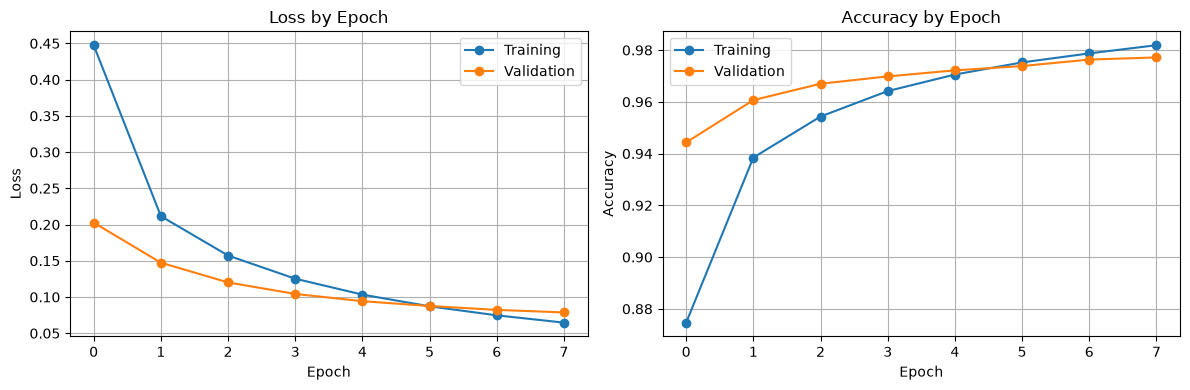

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history['loss'], marker='o', label='Training')
axes[0].plot(history.history['val_loss'], marker='o', label='Validation')
axes[0].set_title('Loss by Epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history.history['accuracy'], marker='o', label='Training')
axes[1].plot(history.history['val_accuracy'], marker='o', label='Validation')
axes[1].set_title('Accuracy by Epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

Result

The feed-forward neural network was trained on MNIST using SGD and evaluated on the test set. 
Record the test accuracy and classification report shown above.
The graphs show training and validation loss and accuracy across epochs.